# Real ALV correlations → conditional motion index

All390 complete real four-channel instrument recordings are reconstructed. The sample is unknown. We estimate coherence β and the conditional product F=αD, with α fixed to1. There is **no physical ground truth**. Source CDE method output is only a numerical comparison. The original ALV reader/preprocessing and the independent original mcgeometry inverse are explicitly combined; this is not a same-paper same-dataset replication.

In [1]:
from pathlib import Path
import sys,time,json,numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
if not (root/'src').exists():root=root.parent
sys.path.insert(0,str(root))
from src.preprocessing import load_data,prepare
from src.solvers import reconstruct
from src.physics_model import correlation
from src.visualization import make_figures,curve_rmse
from scipy.optimize import least_squares
data=load_data(root/'data/raw_data.npz')
weighted,mask=prepare(data)
print({k:(v.shape,str(v.dtype)) for k,v in data.items()},'fit points',mask.sum(axis=1).min(),mask.sum(axis=1).max())

{'g2': ((390, 4, 199), 'float64'), 'lag_times': ((199,), 'float64'), 'countrate': ((390, 4), 'float64')} fit points 65 106


## Physics and numerical method

Multiply scattered field correlation is a normalized source-minus-image Green function, g1(τ)=|G(τ)/G(0)|. G=(3μs′/4π)[exp(−Kr1)/r1−exp(−Kr2)/r2], K²=3μaμs′+6μs′²(2πn/λ0)²Fτ. The intensity correlation is g2=1+βg1². The half-space extrapolation boundary, nominal μa=.1/cm,μs′=10/cm,ρ2.5cm,n1.4 and vacuumλ785nm determine the conditional physical scale. Executable math uses mm, seconds; outputF is cm²/s. The native generic header n1.332 disagrees with the author's nominal analysis n1.4, and its λ0 is invalid: neither is silently called measured optical calibration.

We linearly count-weight channels and use the original contiguous100ns..1ms/lastg2>1.13 support. Full raw early dead-time/tail bins remain available. Joint bounded unweighted least squares starts β.48,F1e-8cm²/s, β∈[.46,.54],F≥0; all390fits retained. The selected original forward source includes the medium refractive index, unlike the unselected Fit-DCS vacuum-wavevector implementation. This numerical SciPy port preserves the original CDE objective/initial/bounds/support with tighter general optimizer termination. No independent α or absolute perfusion can be recovered from this product.

In [2]:
start=time.perf_counter()
fresh=reconstruct(data)
print('Fresh complete390record reconstruction seconds',time.perf_counter()-start)
original=dict(np.load(root/'notebooks/reference_outputs/original_method.npz'))
tighter=dict(np.load(root/'notebooks/reference_outputs/original_tighter.npz'))
print('beta at upper source bound',np.count_nonzero(fresh['beta']>=.54-1e-8),'of390')
print('Flow range cm2/s',fresh['flow_index'].min(),fresh['flow_index'].max())

Fresh complete390record reconstruction seconds 0.5859791999682784
beta at upper source bound 10 of390
Flow range cm2/s 7.177620615543403e-11 7.214069464807806e-09


## Fresh optical-assumption sensitivity

The generic header's n1.332 is an alternative assumption, not independent calibration. Refit **every390curve** with that index, retaining all other assumptions and constraints. This isolates a real conditional-scale ambiguity and does not alter the selected reconstruction or its frozen thresholds.

In [3]:
start=time.perf_counter()
parameters=[]
for y,m in zip(weighted,mask):
    fit=least_squares(lambda x:correlation(data['lag_times'][m],*x,n=1.332)-y[m],[.48,1000.],bounds=([.46,0],[.54,np.inf]),ftol=1e-10,xtol=1e-10,gtol=1e-10,max_nfev=100000)
    if not fit.success:raise RuntimeError(fit.message)
    parameters.append(fit.x)
parameters=np.asarray(parameters)
sensitivity={'flow_index':parameters[:,1][None]/1e11}
print('Fresh all390 sensitivity seconds',time.perf_counter()-start)

Fresh all390 sensitivity seconds 0.5851559001021087


{
  "beta_max_abs_error": 1.8057063718046606e-05,
  "flow_index_max_relative_error": 0.0003142811075382834,
  "predicted_g2_max_abs_error": 5.055909634132938e-05,
  "masked_g2_rmse": 0.056341807989401825,
  "worst_curve_g2_rmse": 0.08851381790494386
}


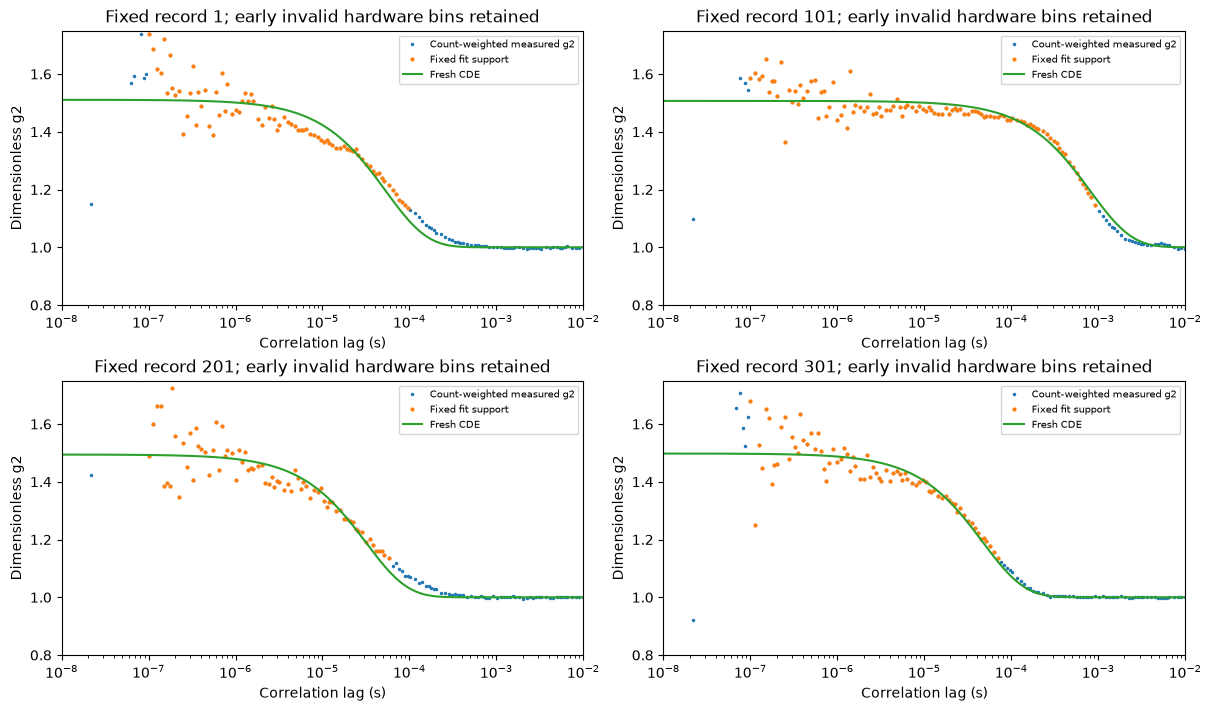

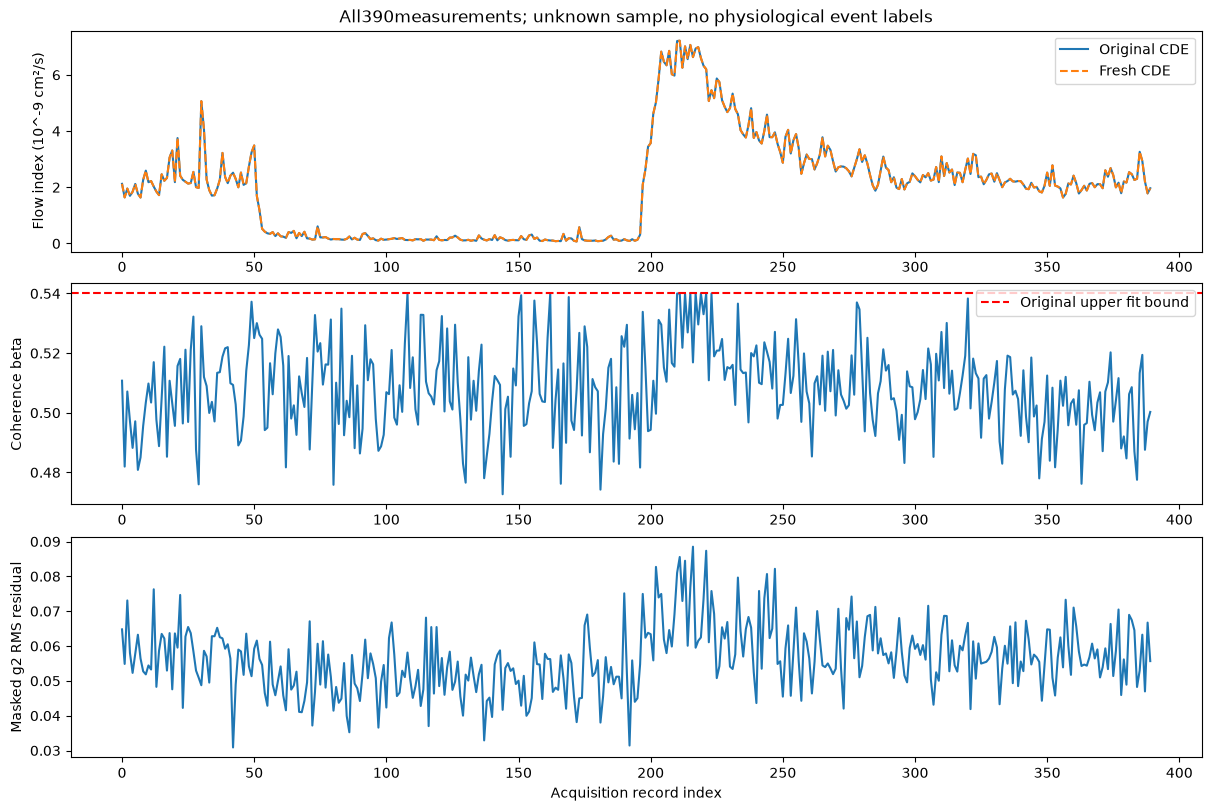

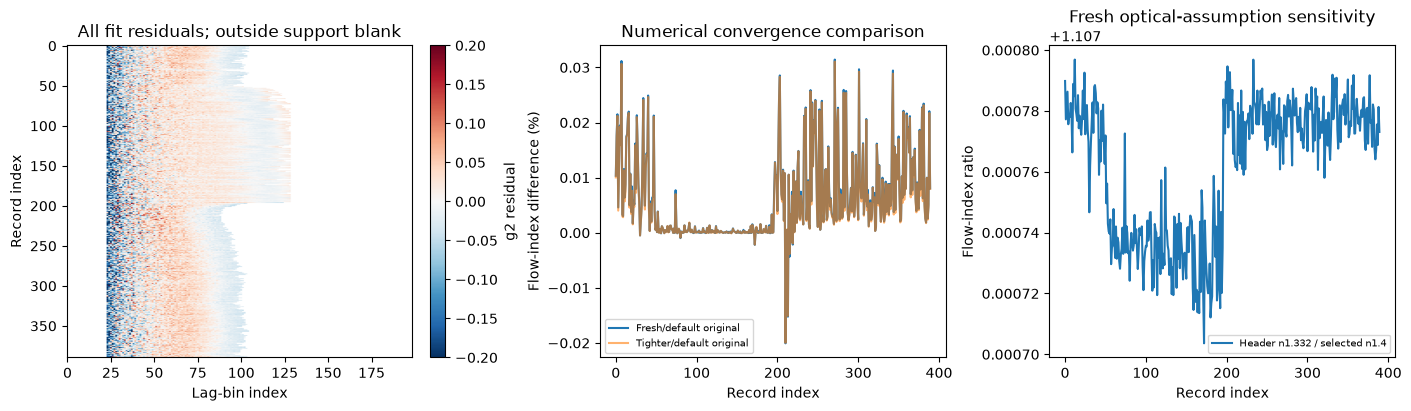

In [4]:
import importlib.util
spec=importlib.util.spec_from_file_location('independent_judge',root/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
metrics=judge.score(fresh,original,weighted,mask)
print(json.dumps(metrics,indent=2))
for figure in make_figures(data,fresh,original,tighter,sensitivity):plt.show()

## Conclusion and limits

The fresh full CDE inverse agrees with the independently executed original numerical reference while preserving noisy observations, every complete recording and constrained coherence fits. The original and tighter-original comparison distinguishes numerical convergence from optical-assumption sensitivity. Residual structure and coherence boundary hits remain visible. The sample identity, actual optical coefficients and physical motion truth are unknown, so these are model-conditioned flow indices rather than human perfusion measurements. Native hardware header values and nominal analysis settings are explicitly distinguished.